# LP3B5: K-Means clustering on sales_data_sample.csv
The number of clusters is chosen with the elbow method.

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

FEATURES = ["QUANTITYORDERED", "PRICEEACH", "SALES", "MSRP"]
MAX_K = 10
print(df.head())
df = pd.read_csv("sales_data_sample.csv", encoding="latin-1")  # file is not UTF-8
df = df.dropna(subset=FEATURES)
X = StandardScaler().fit_transform(df[FEATURES])               # equal weight for every feature
df[FEATURES].describe()

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ... ADDRESSLINE2  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...          NaN   
1    5/7/2003 0:00  Shipped       2         5     2003  ...          NaN   
2    7/1/2003 0:00  Shipped       3         7     2003  ...          NaN   
3   8/25/2003 0:00  Shipped       3         8     2003  ...          NaN   
4  10/10/2003 0:00  Shipped       4        10     2003  ...          NaN   

            CITY STATE POSTALCODE COUNTRY TERRITORY CONTACTLASTNAME  \
0            NYC    NY      10022     U

,QUANTITYORDERED,PRICEEACH,SALES,MSRP
count,2823.000000,2823.000000,2823.000000,2823.000000
mean,35.092809,83.658544,3553.889072,100.715551
std,9.741443,20.174277,1841.865106,40.187912
min,6.000000,26.880000,482.130000,33.000000
25%,27.000000,68.860000,2203.430000,68.000000
50%,35.000000,95.700000,3184.800000,99.000000
75%,43.000000,100.000000,4508.000000,124.000000
max,97.000000,100.000000,14082.800000,214.000000


## Elbow method
Inertia (within-cluster sum of squares) for k = 1..10. The elbow is the point farthest from the straight line joining the first and last points.

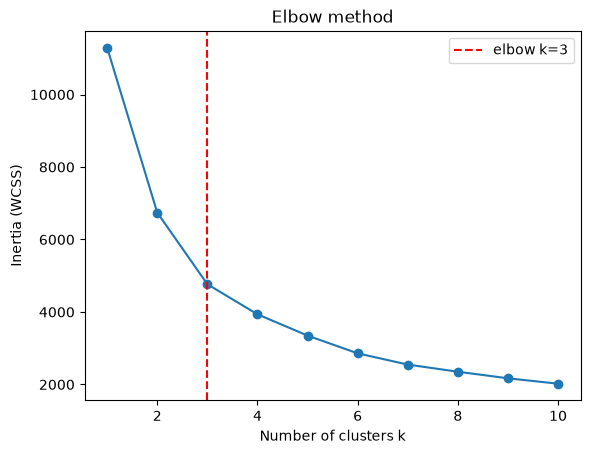

Optimal number of clusters: 3


In [5]:
ks = list(range(1, MAX_K + 1))
inertia = [KMeans(k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]

x0, y0, x1, y1 = ks[0], inertia[0], ks[-1], inertia[-1]
dist = [abs((y1 - y0) * k - (x1 - x0) * i + x1 * y0 - y1 * x0) for k, i in zip(ks, inertia)]
best_k = ks[dist.index(max(dist))]

plt.plot(ks, inertia, "o-")
plt.axvline(best_k, ls="--", c="r", label=f"elbow k={best_k}")
plt.title("Elbow method"); plt.xlabel("Number of clusters k"); plt.ylabel("Inertia (WCSS)")
plt.legend(); plt.show()
print(f"Optimal number of clusters: {best_k}")

## Final K-Means model

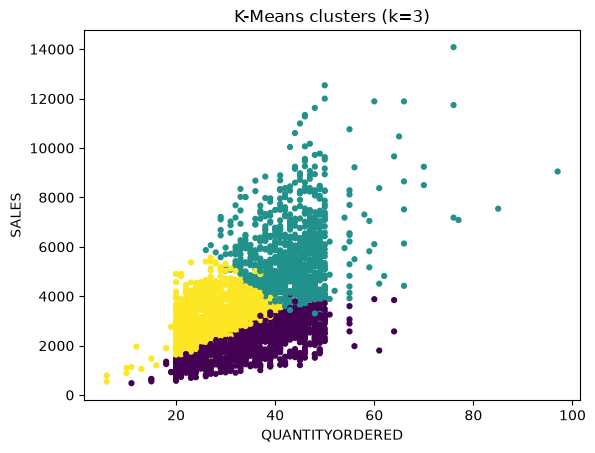

,QUANTITYORDERED,PRICEEACH,SALES,MSRP,SIZE
CLUSTER,,,,,
0,35.21,59.55,2101.08,64.15,975
1,43.72,97.48,5720.08,127.89,852
2,27.60,95.44,3123.06,113.27,996


In [6]:
df["CLUSTER"] = KMeans(best_k, n_init=10, random_state=0).fit_predict(X)

plt.scatter(df["QUANTITYORDERED"], df["SALES"], c=df["CLUSTER"], cmap="viridis", s=12)
plt.title(f"K-Means clusters (k={best_k})"); plt.xlabel("QUANTITYORDERED"); plt.ylabel("SALES")
plt.show()

df.groupby("CLUSTER")[FEATURES].mean().round(2).assign(SIZE=df["CLUSTER"].value_counts())